In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import math
import numpy as np

In [37]:
df = pd.read_csv("kc_house_data.csv")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [38]:
df = df.drop(columns=['id','date','lat','long','zipcode','sqft_above'])
df = df.astype({'floors':int, 'bathrooms':int})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          21613 non-null  float64
 1   bedrooms       21613 non-null  int64  
 2   bathrooms      21613 non-null  int64  
 3   sqft_living    21613 non-null  int64  
 4   sqft_lot       21613 non-null  int64  
 5   floors         21613 non-null  int64  
 6   waterfront     21613 non-null  int64  
 7   view           21613 non-null  int64  
 8   condition      21613 non-null  int64  
 9   grade          21613 non-null  int64  
 10  sqft_basement  21613 non-null  int64  
 11  yr_built       21613 non-null  int64  
 12  yr_renovated   21613 non-null  int64  
 13  sqft_living15  21613 non-null  int64  
 14  sqft_lot15     21613 non-null  int64  
dtypes: float64(1), int64(14)
memory usage: 2.5 MB


In [39]:
train = df.sample(frac=0.8,random_state=222)
test = df.drop(train.index)
test.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
2,180000.0,2,1,770,10000,1,0,0,3,6,0,1933,0,2720,8062
3,604000.0,4,3,1960,5000,1,0,0,5,7,910,1965,0,1360,5000
10,662500.0,3,2,3560,9796,1,0,0,3,8,1700,1965,0,2210,8925
11,468000.0,2,1,1160,6000,1,0,0,4,7,300,1942,0,1330,6000
12,310000.0,3,1,1430,19901,1,0,0,4,7,0,1927,0,1780,12697


In [40]:
X_train = train.drop(columns=['price'])
Y_train = train['price'] 

X_test = test.drop(columns=['price'])
Y_test = test['price'] 

Y_train.info()

<class 'pandas.core.series.Series'>
Int64Index: 17290 entries, 8592 to 19662
Series name: price
Non-Null Count  Dtype  
--------------  -----  
17290 non-null  float64
dtypes: float64(1)
memory usage: 270.2 KB


In [41]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [54]:
X_tr = np.array(X_train_scaled)
y_tr = np.array(Y_train)
X_te = np.array(X_test_scaled)
y_te = np.array(Y_test)

num_samples, num_features = X_tr.shape

weights = np.zeros(num_features)
learning_rate = 0.05
bias = 0.0
iterations = 1000
mse_history = []

for epoch in range(iterations):
    
    y_pred = (X_tr @ weights) + bias 
    error = y_pred - y_tr
    mse = np.mean(error ** 2)
    mse_history.append(mse)
    
    dw = (2 / num_samples) * (X_tr.T @ error)
    db = (2 / num_samples) * np.sum(error)
    
    weights -= learning_rate * dw
    bias -= learning_rate * db

y_pred_test = (X_te @ weights) + bias
test_mse = np.mean((y_pred_test - y_te) ** 2)
test_rmse = np.sqrt(test_mse)

print(f"Weights:{np.round(weights, 2)}")
print(f"Bias:{bias:,.2f}")
print(f"MSE:{test_mse:,.2f}")
print(f"RMSE:{test_rmse:,.2f}")

Weights:[  53622.3   457514.74  665141.16   20429.75  171387.72  290802.87
  345246.07   63347.23  757530.98  333582.78 -338711.39   73560.02
  656878.6     2087.63]
Bias:-172,386.67
MSE:51,015,366,370.03
RMSE:225,865.81


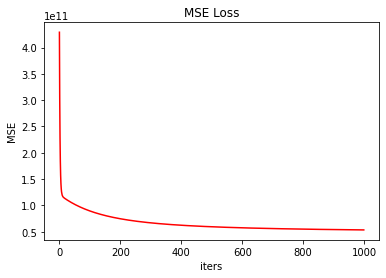

In [55]:
plt.plot(mse_history, color='red')
plt.title("MSE Loss")
plt.xlabel("iters")
plt.ylabel("MSE")
plt.show()